# The 27 cases of the studio: the regime each one lands in, where the engine refuses, and what the setting does

**Question:** Which operating regimes do the 27 baked cases cover, where does the engine refuse to give a confident number, and how far does the closed-side setting move product size and throughput?

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic
- **Reading time:** about 30 minutes

## Objectives

By the end of this notebook you can:

- read the index and the manifests of the committed cases and arrange them as a matrix of machine, stage and operating point;
- run the live engine over the whole matrix and read the regime, the validity and the flag codes it gives each case;
- measure what a 15 percent change of the closed-side setting does to P80 and throughput across machines, and find the case where it breaks the regime;
- apply the expectation gate of the pipeline to a live result, and say why an authored range is not the engine's own value.

## Setup

This notebook uses the same two libraries as the first one. The pipeline modules it imports are the case manifest helpers (`core/manifest.py`, `core/trace.py`) and the expectation gate (`core/expect.py`), next to the engine.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

The cell imports them and prints the library versions.

In [1]:
# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from collections import Counter
from dataclasses import replace
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# The notebook sits three folders below the repository root; the pipeline is imported by its path
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.model.crusher import evaluate, Operating
from pipeline.core.manifest import flag_codes
from pipeline.core.trace import metrics_of
from pipeline.core.expect import check, ExpectationError
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Data

The index of the baked cases and one manifest per case, 28 files in all. Owner: this repository, https://github.com/fsantibanezleal/CAOS_ChancaDEM. Licence class: MIT; the committed artifacts are written by the pipeline from the parameters of each case. The HP500 manifests carry the ten surveys of Rocha et al. (2024), CC BY 4.0, https://doi.org/10.3390/min14090919, and say so in their `source` block. Files read: `data/derived/manifests/index.json` and `data/derived/manifests/<case>.json` for each case the index lists.

The next cell reads the index and then every manifest it points to, and keeps them in one dictionary keyed by case id.

In [2]:
# Read the index, then each manifest it lists; a missing file stops the notebook with its path
derived = ROOT / "data" / "derived"
index = json.loads((derived / "manifests" / "index.json").read_text(encoding="utf-8"))
manifests = {}
for entry in index["cases"]:
    manifests[entry["case_id"]] = json.loads((derived / entry["manifest_path"]).read_text(encoding="utf-8"))
print("cases in the index:", index["n_cases"], "| default case:", index["default_case"])

cases in the index: 27 | default case: S01


## Method

**Step 1, the matrix.** Each manifest holds the operating point (`params`), the stage of the circuit (primary, secondary, tertiary or control), whether the case is synthetic or a real survey, and a `control` tag for the three cases that exist to test the engine's refusals. Counting the cases by stage and by machine is the first view of what the studio covers: it shows whether the secondary cone, the workhorse of the circuit, has the most cases, and how many cases are real data.

In [3]:
# Count the cases by stage and by machine, and list the real ones and the controls
by_stage = Counter(m["stage"] for m in manifests.values())
by_machine = Counter(m["params"]["machine"] for m in manifests.values())
real = [k for k, m in manifests.items() if m["real_or_synthetic"] == "real"]
print("by stage:", dict(by_stage))
print("by machine:", dict(by_machine))
print("real surveys:", len(real), "| controls:", [k for k, m in manifests.items() if m["control"]])

by stage: {'control': 3, 'primary': 4, 'tertiary': 4, 'secondary': 16}
by machine: {'cone-sec': 19, 'gyratory': 2, 'cone-short-head': 2, 'jaw': 2, 'cone-tert': 2}
real surveys: 10 | controls: ['CI1', 'CK1', 'CP1']


**Step 2, the live run.** The cell runs the engine on every operating point of the matrix, in the index order. Two things matter for each result: whether the engine called the point `valid`, and which flag codes explain a refusal. `flag_codes` turns the engine's flag texts into the stable codes that the manifest stores. A case is called clean here when the engine gives it no flag.

In [4]:
# Evaluate the live engine on every case and keep result, regime and flags
live = {k: evaluate(Operating(**m["params"])) for k, m in manifests.items()}
# The vendor-minimum and reduction-ratio codes are advisory: the point stays valid, so they are counted apart
ADVISORY = {"css_below_vendor_minimum", "reduction_ratio_above_typical"}
flagged = {k: [c for c in flag_codes(r) if c not in ADVISORY] for k, r in live.items()}
flagged = {k: codes for k, codes in flagged.items() if codes}
advised = sorted(k for k, r in live.items() if ADVISORY & set(flag_codes(r)))
print("clean cases:", len(live) - len(flagged), "of", len(live))
print("cases with an advisory warning only (still valid):", len([k for k in advised if k not in flagged]))
for k, codes in flagged.items():
    print(f"{k:9s} regime={live[k].regime:12s} valid={live[k].valid!s:5s} {codes}")

clean cases: 23 of 27
cases with an advisory warning only (still valid): 7
CI1       regime=invalid      valid=False ['css_ge_feed_top', 'f80_lt_css']
CP1       regime=pass-through valid=False ['pass_through', 'f80_lt_css']
G02       regime=pass-through valid=False ['pass_through', 'f80_lt_css']
HP500-03  regime=pass-through valid=False ['pass_through', 'f80_lt_css']


The four flagged cases are not defects. Two are the controls built to be refused: CP1 sets a closed-side setting wider than the feed's F80, so most of the material is not gripped, and CI1 sets it wider than the feed top size, so nothing is gripped at all. The other two, G02 and HP500-03, are ordinary cases that sit on the same edge: their F80 is at or below the setting, and the engine says so instead of reporting a confident reduction. Apart from these, the engine adds two advisory warnings, a setting below the vendor's minimum or a reduction ratio above the stage's typical ceiling, which leave the point valid; the count printed above says how many cases carry one. The figure places all 27 points by their product size and throughput and marks the flagged ones.

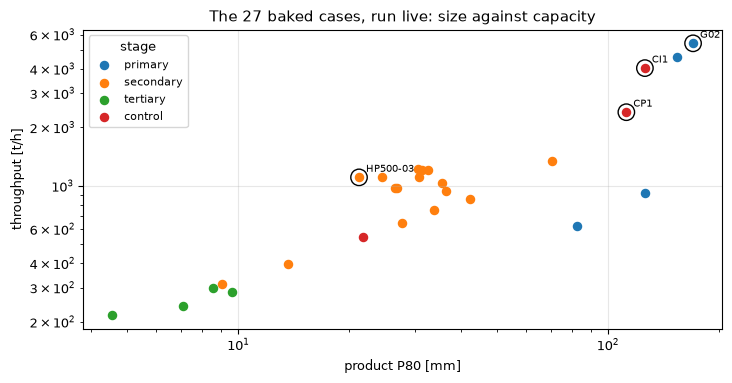

In [5]:
# Scatter the 27 live results by product P80 and throughput, one colour per stage, flagged cases circled
fig, ax = plt.subplots()
for stage in ("primary", "secondary", "tertiary", "control"):
    ids = [k for k, m in manifests.items() if m["stage"] == stage]
    ax.scatter([live[k].p80 for k in ids], [live[k].throughput_tph for k in ids], label=stage, s=34)
for k in flagged:
    ax.scatter([live[k].p80], [live[k].throughput_tph], s=140, facecolors="none", edgecolors="black")
    ax.annotate(k, (live[k].p80, live[k].throughput_tph), fontsize=7, xytext=(5, 4), textcoords="offset points")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("product P80 [mm]")
ax.set_ylabel("throughput [t/h]")
ax.set_title("The 27 baked cases, run live: size against capacity")
ax.legend(title="stage", fontsize=8)
fig.tight_layout()
plt.show()

The cloud has the shape a crushing circuit should have: the machines that make the finest products (the tertiary and short-head cones, P80 under 10 mm) move a few hundred tonnes per hour, the secondary cones sit in the middle, and the gyratory and jaw crushers of the primary stage give the coarsest products, 82 to 170 mm, at 600 to 5400 t/h. The circles show that the refusals are not outliers in the cloud: a flagged point can look like any other, which is why the flag, and not the position, is what tells a reader to distrust it.

**Step 3, the variants.** The studio lets a reader move the closed-side setting 15 percent tighter or wider than the case's own value. The cell runs each of the 23 clean cases at both settings and keeps the ratio of the wide-setting result to the tight-setting result, for P80 and for throughput. The two settings differ by a factor 1.15 / 0.85 = 1.353, so a ratio near 1.35 would mean that the quantity follows the setting one to one.

In [6]:
# Run each clean case 15 % tighter and 15 % wider in its closed-side setting and compare the two results
clean = [k for k in live if k not in flagged]
open_over_tight, leaves_valid = {}, []
for k in clean:
    op = Operating(**manifests[k]["params"])
    tight = evaluate(replace(op, css_mm=op.css_mm * 0.85))
    wide = evaluate(replace(op, css_mm=op.css_mm * 1.15))
    open_over_tight[k] = (wide.p80 / tight.p80, wide.throughput_tph / tight.throughput_tph)
    if not wide.valid:
        leaves_valid.append((k, wide.regime))
p80_ratio = np.array([v[0] for v in open_over_tight.values()])
tph_ratio = np.array([v[1] for v in open_over_tight.values()])
p80_stats = (p80_ratio.min().round(3), np.median(p80_ratio).round(3), p80_ratio.max().round(3))
tph_stats = (tph_ratio.min().round(3), np.median(tph_ratio).round(3), tph_ratio.max().round(3))
print("P80 ratio, wide over tight (min, median, max):", *p80_stats)
print("throughput ratio (min, median, max):", *tph_stats)
print("coarser product at the wide setting:", int((p80_ratio > 1).sum()), "of", len(clean))
print("cases that leave the valid regime at the wide setting:", leaves_valid)

P80 ratio, wide over tight (min, median, max): 1.066 1.321 1.391
throughput ratio (min, median, max): 1.149 1.24 1.319
coarser product at the wide setting: 23 of 23
cases that leave the valid regime at the wide setting: [('G01', 'pass-through')]


In all 23 clean cases the wider setting gives the coarser product. The median ratio of P80 is 1.32, close to the proportional 1.35, so the setting is the main lever on product size across machines and stages; the median ratio of throughput is 1.24, a weaker but consistent response. The one case that leaves the valid regime shows the edge of the lever: G01, a gyratory, is a clean case at its own setting, but 15 percent wider it falls into the pass-through regime and the engine marks it invalid. The next cell traces the whole response for the reference case, from half to one and a half times its setting.

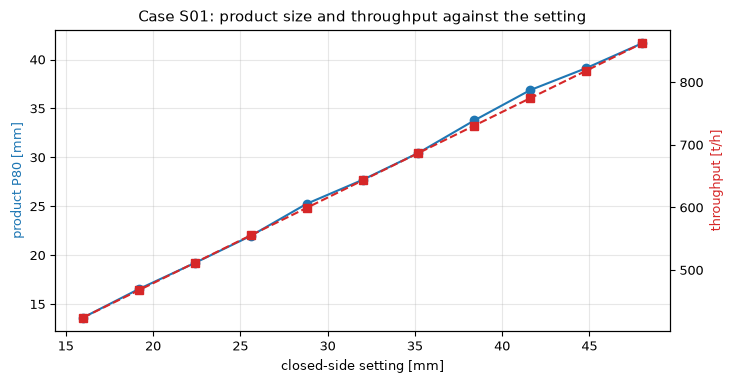

tightest setting 16 mm: P80 13.63 mm, throughput 424 t/h
widest setting 48 mm: P80 41.65 mm, throughput 862 t/h
power at the tightest and the widest setting [kW]: 341 251


In [7]:
# Sweep the closed-side setting of S01 from 0.5 to 1.5 of its own value, and plot P80 and throughput
base = Operating(**manifests["S01"]["params"])
settings = base.css_mm * np.linspace(0.5, 1.5, 11)
runs = [evaluate(replace(base, css_mm=float(c))) for c in settings]
fig, ax = plt.subplots()
ax.plot(settings, [r.p80 for r in runs], "o-", color="tab:blue")
ax.set_xlabel("closed-side setting [mm]")
ax.set_ylabel("product P80 [mm]", color="tab:blue")
twin = ax.twinx()
twin.plot(settings, [r.throughput_tph for r in runs], "s--", color="tab:red")
twin.set_ylabel("throughput [t/h]", color="tab:red")
twin.grid(False)
ax.set_title("Case S01: product size and throughput against the setting")
fig.tight_layout()
plt.show()
for label, r, css in (("tightest", runs[0], settings[0]), ("widest", runs[-1], settings[-1])):
    print(f"{label} setting {css:.0f} mm: P80 {r.p80:.2f} mm, throughput {r.throughput_tph:.0f} t/h")
print("power at the tightest and the widest setting [kW]:", round(runs[0].power_kw), round(runs[-1].power_kw))

P80 rises almost linearly with the setting, from 13.63 mm at 16 mm to 41.65 mm at 48 mm, and the throughput rises from 424 to 862 t/h. The curves answer the plant question in one picture: opening the crusher gives more tonnes and a coarser product, and the power, printed under the figure, falls from 341 kW to 251 kW because there is less size reduction to pay for. The figure does not show where the product stops meeting the next stage's feed requirement; that depends on the circuit, which this product does not model.

**Step 4, the expectation gate.** Every case states, in its manifest, the range in which each of several result metrics must fall, written from engineering relations or measurements and never from the engine's own value (`core/expect.py`). The bake fails on a value outside its range. The cell reuses the same function, `check`, on the live result of each case: it returns the ranges when all metrics are inside and raises `ExpectationError` naming the ones that are not.

In [8]:
# Apply the pipeline's expectation gate to the live results; collect what falls outside its range
outside = {}
for k, m in manifests.items():
    try:
        check(k, {name: tuple(rng) for name, rng in m["expect"].items()}, metrics_of(live[k]))
    except ExpectationError as exc:
        outside[k] = str(exc)
print("cases inside every authored range:", len(manifests) - len(outside), "of", len(manifests))
print("metrics gated in S01:", sorted(manifests["S01"]["expect"]))

cases inside every authored range: 27 of 27
metrics gated in S01: ['p80_mm', 'reduction_ratio', 'throughput_tph']


**Step 5, a reproduction check, outside the lesson.** The manifests store each result rounded to six significant digits (`metrics`). The live engine works in double precision, so the two cannot be identical, and the question is how far apart they may be without anything being wrong. A number kept to six significant digits is off by at most half a unit of its sixth digit; relative to the number that is at most 5e-6, reached when the leading digit is 1. The cell computes the relative difference between the live value and the stored one for every case and metric, and prints the worst per metric. It is the notebook's one reproduction check: the test suite repeats the same comparison on every change, so nothing below depends on it.

In [9]:
# Reproduction check: the unrounded live value against the stored one, worst case per metric
READOUTS = ("p80_mm", "p50_mm", "p20_mm", "f80_mm",
            "reduction_ratio", "throughput_tph", "power_kw", "specific_energy_kwh_t")
FIELD = {"p80_mm": "p80", "p50_mm": "p50", "p20_mm": "p20", "f80_mm": "f80"}
worst, exact, total = {}, 0, 0
for k, m in manifests.items():
    rounded = metrics_of(live[k])
    for name in READOUTS:
        raw = getattr(live[k], FIELD.get(name, name))
        stored = m["metrics"][name]
        rel = abs(raw - stored) / max(abs(stored), 1e-12)
        if rel > worst.get(name, (0.0, ""))[0]:
            worst[name] = (rel, k)
        total += 1
        exact += rounded[name] == stored
for name, (rel, k) in worst.items():
    print(f"{name:24s} {rel:.2e}  ({k})")
print("largest of all:", f"{max(r for r, _ in worst.values()):.2e}")
print("identical after the six-digit rounding:", exact, "of", total)

p80_mm                   3.53e-06  (J01)
p50_mm                   3.36e-06  (HP500-10)
p20_mm                   2.65e-06  (J01)
f80_mm                   2.97e-06  (CI1)
throughput_tph           4.56e-06  (HP500-08)
specific_energy_kwh_t    4.21e-06  (CI1)
reduction_ratio          3.72e-06  (CP1)
power_kw                 3.68e-06  (J02)
largest of all: 4.56e-06
identical after the six-digit rounding: 216 of 216


All eight worst differences are under the 5e-6 that six stored digits allow, so the live engine and the committed artifacts agree to the digits that were stored. That is what a reproducible bake looks like, and it is all the check says: both numbers come from the same engine, so it cannot say whether either is right. The oracles of topic 02 and topic 04, and the plant measurements of topic 05, are the independent references that can.

## Results

**Answer:** the 27 cases are 4 primary, 16 secondary (6 synthetic and the 10 HP500 surveys), 4 tertiary and 3 controls. The live engine calls 23 of them clean and flags 4: CI1 and CP1 (the controls), G02 and HP500-03, all with the code `f80_lt_css`, a feed whose F80 is at or below the closed-side setting. Every one of the 27 results is inside its authored expectation range. A 15 percent wider closed-side setting gives the coarser product in 23 of 23 clean cases, with a median P80 ratio of 1.32 and a median throughput ratio of 1.24; on the reference case S01, opening the setting from 16 to 48 mm moves P80 from 13.63 to 41.65 mm and throughput from 424 to 862 t/h, while the power falls from 341 to 251 kW. One clean case, G01, leaves the valid regime at the wide setting.

Two readings follow. First, the engine's refusals are part of its behaviour and are covered by cases: a reader who sets a machine wider than its feed gets a flag and a pass-through regime, not a confident product size. Second, the setting is the main lever on product size across machines, and the one place it breaks is the regime boundary, which is where a validator should look before trusting a sweep. The 10 real surveys, where a plant measured the throughput, are the evidence on whether the engine is right, and they are the subject of topic 05.

## Summary

The case matrix is the studio's coverage map: three stages, five machines, a real lane of ten surveys and three controls that exist to be refused. The manifest helpers and the expectation gate are shared pipeline code, so a notebook reuses what the bake uses. The setting sweep is the first look at a lever of the method, and it already shows where a lever stops being safe to turn. Topic 02 starts with the feed.

## References

- Whiten, W. J. (1972), The simulation of crushing plants with models developed using multiple spline regression, Journal of the South African Institute of Mining and Metallurgy 72(10), 257-264. https://www.saimm.co.za/Conferences/Apcom72/317-Whiten.pdf
- Napier-Munn, T. J., Morrell, S., Morrison, R. D., Kojovic, T. (1996), Mineral Comminution Circuits: Their Operation and Optimisation, JKMRC. https://search.worldcat.org/title/37081193
- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919